# Introduction

Column name|Question text
---|---
ResponseId|Randomized respondent ID number.
MainBranch|Which of the following options best describes you today?
Age|What is your age?
Employment|What is your current employment status?
RemoteWork|How often do you work remotely?
Check|Various verification or check questions related to survey consistency.
CodingActivities|What coding activities do you engage in (hobby, professional, and open-source contributions)?
EdLevel|What is the highest level of formal education you have completed?
LearnCode|How did you learn to code?
LearnCodeOnline|Have you used online resources to learn coding?
TechDoc|How do you use technical documentation?
YearsCode|How many years have you been coding?
YearsCodePro|How many years have you coded professionally?
DevType|What is your role or type of development work you do?
OrgSize|What is the size of the organization you work for?
PurchaseInfluence|How much influence do you have on purchasing technology at your company?
BuyNewTool|How does your company decide whether to buy new tools or technology?
BuildvsBuy|Does your company prefer to build or buy software?
TechEndorse|Do you endorse any specific technologies at your company?
Country|In which country do you reside?
Currency|Which currency do you use day-to-day?
CompTotal|What is your current total compensation (salary, bonuses, and so on)?
LanguageHaveWorkedWith|Which programming languages have you worked with in the past year?
LanguageWantToWorkWith|Which programming languages do you want to work with in the future?
LanguageAdmired|Which programming languages do you admire most?
DatabaseHaveWorkedWith|Which database technologies have you worked with in the past year?
DatabaseWantToWorkWith|Which database technologies do you want to work with in the future?
DatabaseAdmired|Which database technologies do you admire most?
PlatformHaveWorkedWith|Which platforms have you worked with in the past year?
PlatformWantToWorkWith|Which platforms do you want to work with in the future?
PlatformAdmired|Which platforms do you admire most?
WebframeHaveWorkedWith|Which web frameworks have you worked with in the past year?
WebframeWantToWorkWith|Which web frameworks do you want to work with in the future?
WebframeAdmired|Which web frameworks do you admire most?
EmbeddedHaveWorkedWith|Which embedded systems have you worked with in the past year?
EmbeddedWantToWorkWith|Which embedded systems do you want to work with in the future?
EmbeddedAdmired|Which embedded systems do you admire most?
MiscTechHaveWorkedWith|Which miscellaneous technologies have you worked with in the past year?
MiscTechWantToWorkWith|Which miscellaneous technologies do you want to work with in the future?
MiscTechAdmired|Which miscellaneous technologies do you admire most?
OpSysPersonal|What operating systems do you use for personal tasks?
OpSysProfessional|What operating systems do you use for professional tasks?
SOVisitFreq|How frequently do you visit Stack Overflow?
SOAccount|Do you have a Stack Overflow account?
SOPartFreq|How often do you participate in Q&A on Stack Overflow?
AISelect|How do you feel about artificial intelligence tools for development?
AIBen|What benefits have you experienced from using AI tools?
AIChallenges|What challenges have you faced while using AI tools?
JobSat|How satisfied are you with your current job?

# Data Loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import scipy

# Load the dataset directly from the URL
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"

df = pd.read_csv(file_path)

In [2]:
# Ensure data has been loaded correctly
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


In [3]:
# Investigate the size of the dataset
df.shape

(65457, 114)

# Data Preparation

In [4]:
# Investigate the data types of columns in the dataset
df.dtypes

ResponseId               int64
MainBranch                 str
Age                        str
Employment                 str
RemoteWork                 str
                        ...   
JobSatPoints_11        float64
SurveyLength               str
SurveyEase                 str
ConvertedCompYearly    float64
JobSat                 float64
Length: 114, dtype: object

In [6]:
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29,
    "35-44 years old": 39,
    "45-54 years old": 49,
    "55-64 years old": 59,
    "65 years or older": 70
}

# Create a new numeric Age column
df['Age_numeric'] = df['Age'].map(age_mapping)

# Calculate the mean age
print("Mean age of developers surveyed:",df['Age_numeric'].mean())

Mean age of developers surveyed: 32.68101635065633


In [7]:
print("Number of unique countries in survey:",len(df['Country'].unique()))

Number of unique countries in survey: 186


In [8]:
# Count the number of duplicate rows in the dataset
print("There are", df.duplicated().sum(), "duplicate rows in the dataset")

There are 20 duplicate rows in the dataset


In [9]:
# Display the first few duplicate rows to understand their structure
print(df[df.duplicated()].head())

       ResponseId                      MainBranch                 Age  \
65437           1  I am a developer by profession  Under 18 years old   
65438           2  I am a developer by profession     35-44 years old   
65439           3  I am a developer by profession     45-54 years old   
65440           4           I am learning to code     18-24 years old   
65441           5  I am a developer by profession     18-24 years old   

                Employment RemoteWork   Check  \
65437  Employed, full-time     Remote  Apples   
65438  Employed, full-time     Remote  Apples   
65439  Employed, full-time     Remote  Apples   
65440   Student, full-time        NaN  Apples   
65441   Student, full-time        NaN  Apples   

                                        CodingActivities  \
65437                                              Hobby   
65438  Hobby;Contribute to open-source projects;Other...   
65439  Hobby;Contribute to open-source projects;Other...   
65440                     

In [10]:
# Identify duplicate response pattens based on the MainBranch, Employment, and RemoteWork columns
pattern_cols = ['MainBranch', 'Employment', 'RemoteWork']
groups = df.groupby(pattern_cols)
duplicate_patterns = groups.filter(lambda x: len(x) > 1)
other_cols = [c for c in df.columns if c not in pattern_cols]
variation = (duplicate_patterns.groupby(pattern_cols)[other_cols].nunique())
consistency = (variation == 1).mean().sort_values(ascending = False)
print(consistency)

Check                    1.000000
ICorPM                   0.304075
AIThreat                 0.275862
SOAccount                0.266458
AINextLess integrated    0.238245
                           ...   
YearsCodePro             0.025078
TechEndorse              0.025078
BuyNewTool               0.021944
CodingActivities         0.003135
ResponseId               0.000000
Length: 112, dtype: float64


The column Check has a consistency score of 1 indicating that every qualifying group has the same Check value. This column should be investigated and potentially removed from the dataset.

In [20]:
# Investigate the Check column
print(df['Check'].value_counts(dropna = False))
print("There are",df['Check'].nunique(dropna = False), "unique values in the Check column")

Check
Apples    65457
Name: count, dtype: int64
There are 1 unique values in the Check column


The Check column only contains the value "Apples" and so is not useful for analysis and can be removed from the dataset.

In [22]:
# Remove the Check column
df = df.drop(columns = ['Check'], errors = 'ignore')

In [26]:
# Count repeated combinations of the three pattern columns
print("Total rows:", len(df))
print(
    "Rows with shared patterns:",
    df.duplicated(subset=pattern_cols, keep=False).sum()
)

Total rows: 65457
Rows with shared patterns: 65290


Most rows belong to a group sharing the same answers to the columns MainBranch, Employment, and RemoteWork indicating that these columns are unsuitable for identifying unique survey records.

A more suitable column is the ResponseId column:

In [43]:
# Check whether ResponseId is unique
print("Total rows:", len(df))
print("Unique response IDs:", df['ResponseId'].nunique())
print("Missing response IDs:", df['ResponseId'].isna().sum())

# Count exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

repeated_ids = df[
    df.duplicated(subset=['ResponseId'], keep=False)
].sort_values('ResponseId')

print("Rows with repeated IDs:", len(repeated_ids))
print("Number of repeated IDs:", repeated_ids['ResponseId'].nunique())

Total rows: 65457
Unique response IDs: 65437
Missing response IDs: 0
Exact duplicate rows: 20
Rows with repeated IDs: 40
Number of repeated IDs: 20


In [52]:
duplicate_id_check = (
    repeated_ids.groupby('ResponseId')
    .apply(lambda group: group.drop(columns = 'ResponseId', errors = 'ignore')
          .nunique().max() == 1)
)

print("All repeated-ID groups are identical:",
      duplicate_id_check.all())

print("Repeated-ID groups with differing answers:",
      (~duplicate_id_check).sum())

All repeated-ID groups are identical: True
Repeated-ID groups with differing answers: 0


In [55]:
df = df.drop_duplicates().copy()

print("Rows after cleaning:", len(df))
print("Unique response IDs:", df['ResponseId'].nunique())
print("Exact duplicate rows:", df.duplicated().sum())

Rows after cleaning: 65437
Unique response IDs: 65437
Exact duplicate rows: 0


Identify missing values in the dataset.

In [71]:
percentage_missing_values = (df.isnull().sum().sort_values(ascending = False)/len(df))*100
print(percentage_missing_values)

AINextMuch less integrated    98.245641
AINextLess integrated         96.401119
AINextNo change               80.900714
AINextMuch more integrated    79.464217
EmbeddedAdmired               74.428840
                                ...    
MainBranch                     0.000000
Age                            0.000000
Employment                     0.000000
Check                          0.000000
ResponseId                     0.000000
Length: 114, dtype: float64


In [85]:
print(percentage_missing_values[['EdLevel', 'RemoteWork']])

EdLevel        7.110656
RemoteWork    16.246160
dtype: float64
4653


In [86]:
print("Before imputation:")
print(" EdLevel missing value count:", df['EdLevel'].isnull().sum())
print(" RemoteWork missing value count:", df['RemoteWork'].isnull().sum())

# Impute the empty rows in the columns RemoteWork and EdLevel with the most frequent value
for column in ['EdLevel', 'RemoteWork']:
    df[column] = df[column].fillna(df[column].mode()[0])

print("After imputation:")
print(" EdLevel missing value count:", df['EdLevel'].isnull().sum())
print(" RemoteWork missing value count:", df['RemoteWork'].isnull().sum())

Before imputation:
 4653
 10631
After imputation:
 0
 0


Impute missing values in CodingActivities with forward-fill.

In [88]:
print("Missing values in CodingActivities before imputation:",df['CodingActivities'].isnull().sum())
df['CodingActivities'] = df['CodingActivities'].ffill()
print("Missing values in CodingActivities after imputation:",df['CodingActivities'].isnull().sum())

Missing values in CodingActivities before imputation: 10971
Missing values in CodingActivities after imputation: 0


Impute missing values in ConvertedCompYearly with the median value. SHOULD WE REALLY DO THIS????????????

In [26]:
print('Missing values in ConvertedCompYearly before imputation:', df['ConvertedCompYearly'].isnull().sum())
df['ConvertedCompYearly'] = df['ConvertedCompYearly'].fillna(df['ConvertedCompYearly'].median())
print('Missing values in ConvertedCompYearly after imputation:', df['ConvertedCompYearly'].isnull().sum())

Missing values in ConvertedCompYearly before imputation: 42020
Missing values in ConvertedCompYearly after imputation: 0


# Exploratory Analysis

Normalise ConvertedCompYearly using Min-Max Scaling

In [41]:
df['ConvertedCompYearly'].value_counts()

ConvertedCompYearly
64444.0     321
53703.0     308
75184.0     230
85925.0     226
107406.0    208
           ... 
152615.0      1
4364.0        1
15637.0       1
9711.0        1
116844.0      1
Name: count, Length: 6113, dtype: int64

In [42]:
df['ConvertedCompYearly_MinMax'] = (
    (df['ConvertedCompYearly'] - df['ConvertedCompYearly'].min()) /
    (df['ConvertedCompYearly'].max() - df['ConvertedCompYearly'].min())
)
df['ConvertedCompYearly_MinMax'].head()

0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: ConvertedCompYearly_MinMax, dtype: float64

Apply Z-score Normalisation to ConvertedCompYearly

In [43]:
df['ConvertedCompYearly_Z'] = (
    (df['ConvertedCompYearly'] - df['ConvertedCompYearly'].mean()) /
    df['ConvertedCompYearly'].std()
)
df['ConvertedCompYearly_Z'].head()

0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: ConvertedCompYearly_Z, dtype: float64

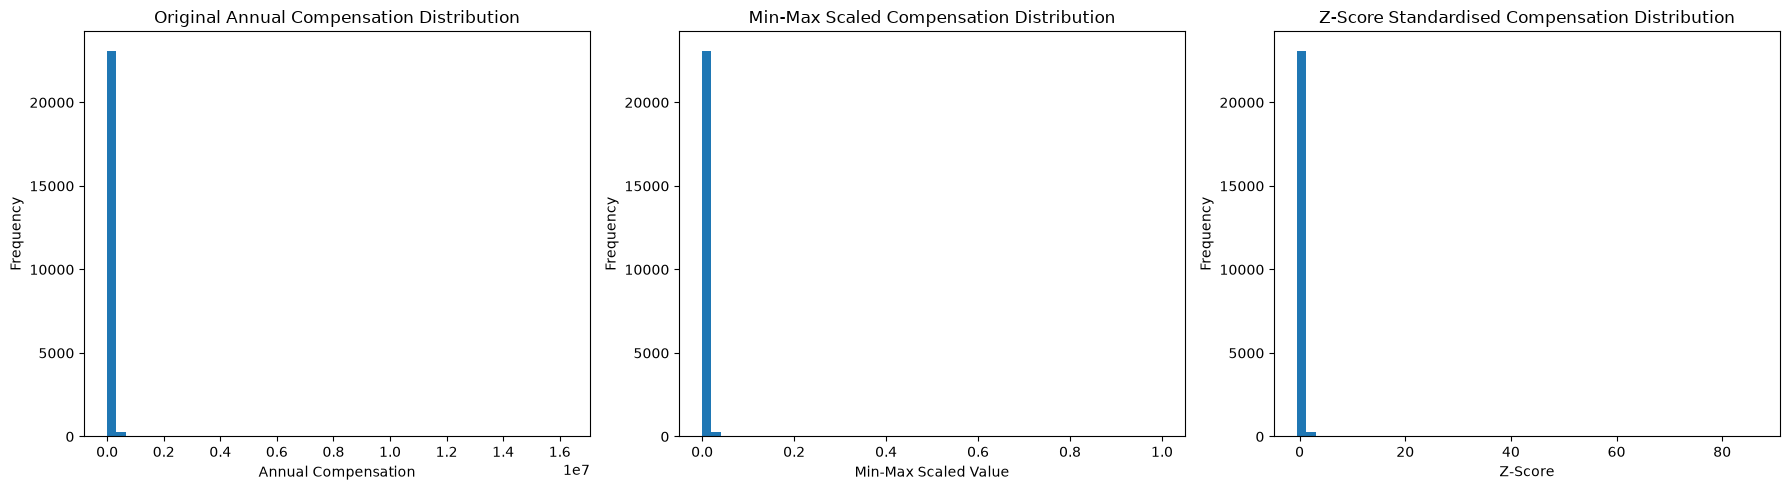

In [58]:
fig, axs = plt.subplots(1, 3, figsize = (18, 5))

axs[0].hist(df['ConvertedCompYearly'], bins = 50)
axs[0].set_title("Original Annual Compensation Distribution")
axs[0].set_xlabel("Annual Compensation")

axs[1].hist(df['ConvertedCompYearly_MinMax'], bins = 50)
axs[1].set_title("Min-Max Scaled Compensation Distribution")
axs[1].set_xlabel("Min-Max Scaled Value")

axs[2].hist(df['ConvertedCompYearly_Z'], bins = 50)
axs[2].set_title("Z-Score Standardised Compensation Distribution")
axs[2].set_xlabel("Z-Score")

for ax in axs:
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

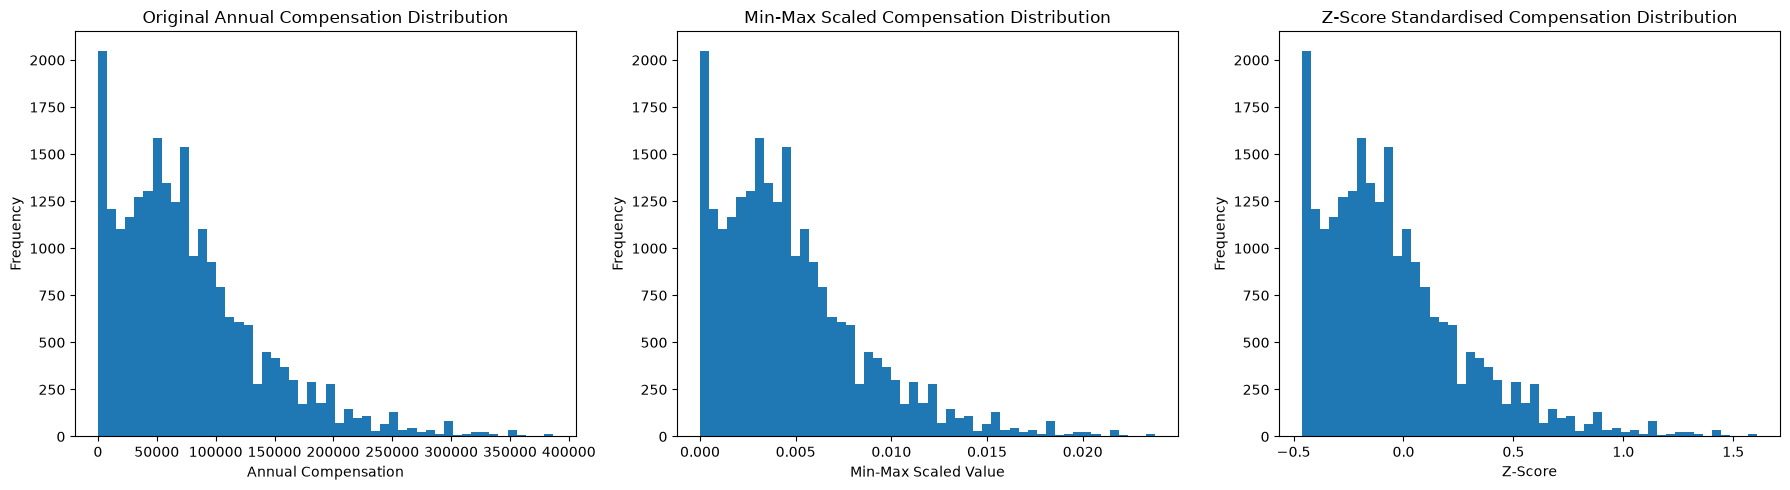

In [57]:
comp = df['ConvertedCompYearly'].dropna()

comp_99 = comp[comp <= comp.quantile(0.99)]

fig, axs = plt.subplots(1, 3 , figsize = (18, 5))

axs[0].hist(comp_99, bins = 50)
axs[0].set_title("Original Annual Compensation Distribution")
axs[0].set_xlabel("Annual Compensation")

axs[1].hist(df.loc[comp_99.index, 'ConvertedCompYearly_MinMax'], bins = 50)
axs[1].set_title("Min-Max Scaled Compensation Distribution")
axs[1].set_xlabel("Min-Max Scaled Value")

axs[2].hist(df.loc[comp_99.index, 'ConvertedCompYearly_Z'], bins = 50)
axs[2].set_title("Z-Score Standardised Compensation Distribution")
axs[2].set_xlabel("Z-Score")

for ax in axs:
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Visualisation

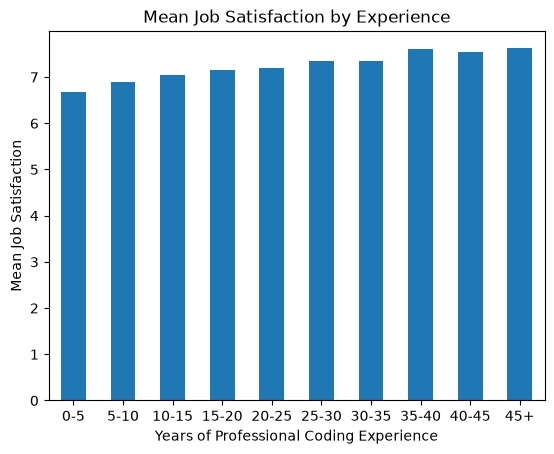

In [3]:
df['YearsCodePro'] = df['YearsCodePro'].replace(
    {'Less than 1 year' : 0.5,
     'More than 50 years' : 51})
df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'])

df['ExperienceRange'] = pd.cut(
    df['YearsCodePro'],
    bins = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, float('inf')],
    labels = ['0-5', '5-10', '10-15', '15-20', '20-25', '25-30', '30-35', '35-40', '40-45', '45+'],
    right = False
)

mean_jobsat = (df.groupby('ExperienceRange', observed = True)['JobSat'].mean())

mean_jobsat.plot(kind = 'bar')
plt.title('Mean Job Satisfaction by Experience')
plt.xlabel('Years of Professional Coding Experience')
plt.ylabel('Mean Job Satisfaction')
plt.xticks(rotation = 0)

plt.show()

In [4]:
correlation = df['JobSat'].corr(df['YearsCodePro'])

print(correlation)

0.10418297570308967


In [5]:
spearman_corr = df['JobSat'].corr(
    df['YearsCodePro'],
    method = 'spearman'
)

print(spearman_corr)

0.11916653388858676


In [5]:
experience_stats = df.groupby(
    'ExperienceRange', observed = True
)['JobSat'].agg(['mean', 'count'])

print(experience_stats)

                     mean  count
ExperienceRange                 
0-5              6.679660   8235
5-10             6.902872   7835
10-15            7.037911   5170
15-20            7.162134   2831
20-25            7.192046   1911
25-30            7.344715   1230
30-35            7.338736    617
35-40            7.608974    312
40-45            7.539394    165
>45              7.618182     55


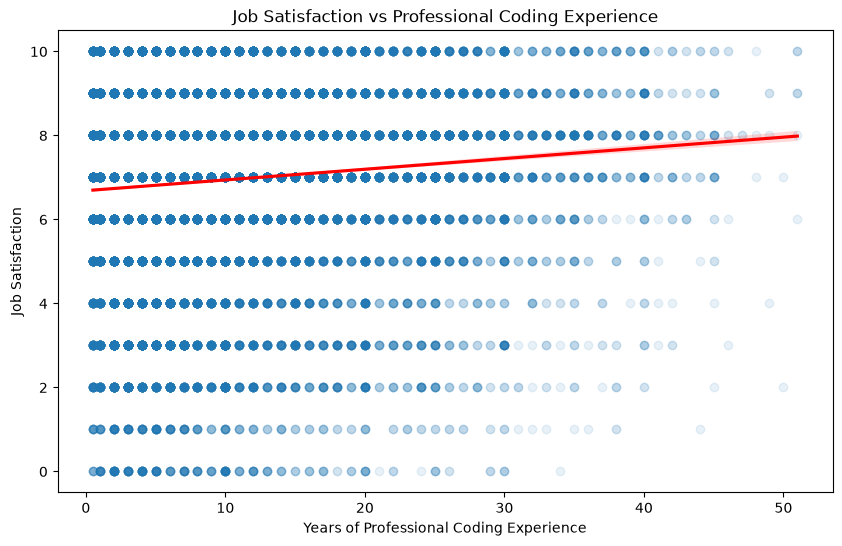

In [10]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='YearsCodePro',
    y='JobSat',
    scatter_kws={'alpha': 0.1},
    line_kws={'color': 'red'}
)

plt.title('Job Satisfaction vs Professional Coding Experience')
plt.xlabel('Years of Professional Coding Experience')
plt.ylabel('Job Satisfaction')

plt.show()

There is a slight positive relationship between professional coding experience and job satisfaction. Both the Pearson correlation coefficient and Spearman correlation coefficient indicate a very week association. Although average job satisfaction increases as professional coding experience increases, the correlation results suggest that professional coding experience is not a particularly strong predictor of job satisfaction.

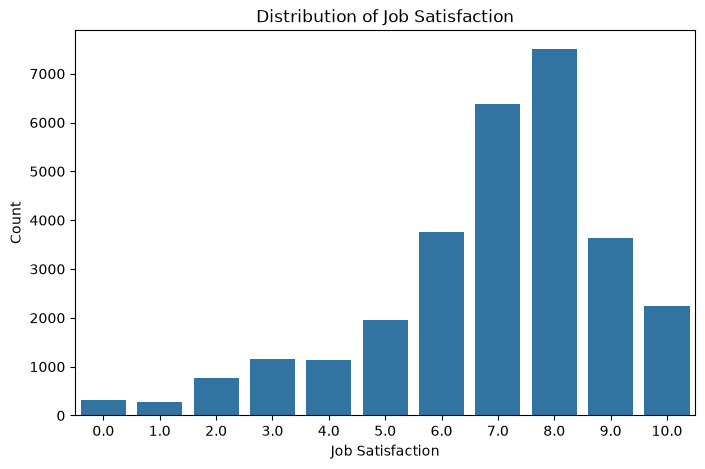

In [6]:
plt.figure(figsize = (8, 5))

sns.countplot(data = df, x = 'JobSat')

plt.title('Distribution of Job Satisfaction')
plt.xlabel('Job Satisfaction')
plt.ylabel('Count')

plt.show()

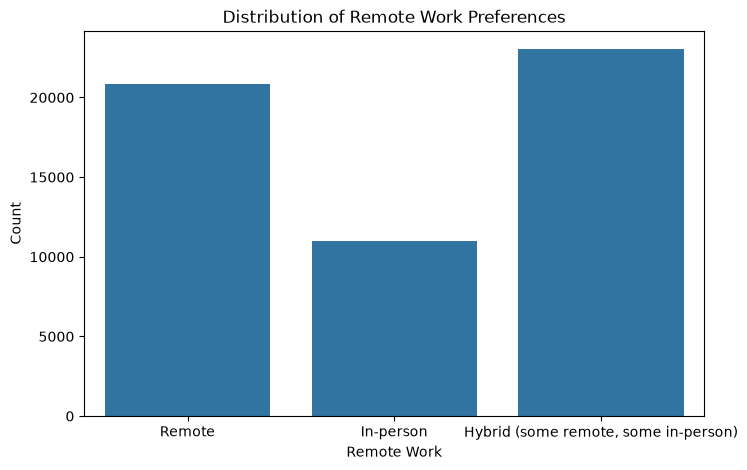

RemoteWork                                          Hybrid (some remote, some in-person)  \
Employment                                                                                 
Employed, full-time                                                                17283   
Employed, full-time;Employed, part-time                                               85   
Employed, full-time;Independent contractor, fre...                                  1331   
Employed, full-time;Independent contractor, fre...                                    80   
Employed, full-time;Independent contractor, fre...                                     0   
...                                                                                  ...   
Student, full-time;Not employed, but looking fo...                                     1   
Student, full-time;Not employed, but looking fo...                                     2   
Student, full-time;Not employed, but looking fo...                              

In [7]:
plt.figure(figsize = (8, 5))

sns.countplot(data = df, x = 'RemoteWork')

plt.title('Distribution of Remote Work Preferences')
plt.xlabel('Remote Work')
plt.ylabel('Count')

plt.show()

employment_remote = pd.crosstab(
    df['Employment'],
    df['RemoteWork'])

print(employment_remote)

In [8]:
languages = (df['LanguageHaveWorkedWith'].dropna().str.split(';').explode())
print(languages.value_counts())

LanguageHaveWorkedWith
JavaScript                 37503
HTML/CSS                   31826
Python                     30727
SQL                        30690
TypeScript                 23160
Bash/Shell (all shells)    20417
Java                       18244
C#                         16320
C++                        13830
C                          12186
PHP                        10954
PowerShell                  8330
Go                          8104
Rust                        7564
Kotlin                      5666
Lua                         3730
Dart                        3595
Assembly                    3233
Ruby                        3147
Swift                       2831
R                           2597
Visual Basic (.Net)         2499
MATLAB                      2378
VBA                         2248
Groovy                      2004
Scala                       1548
Perl                        1482
GDScript                    1402
Objective-C                 1283
Elixir              

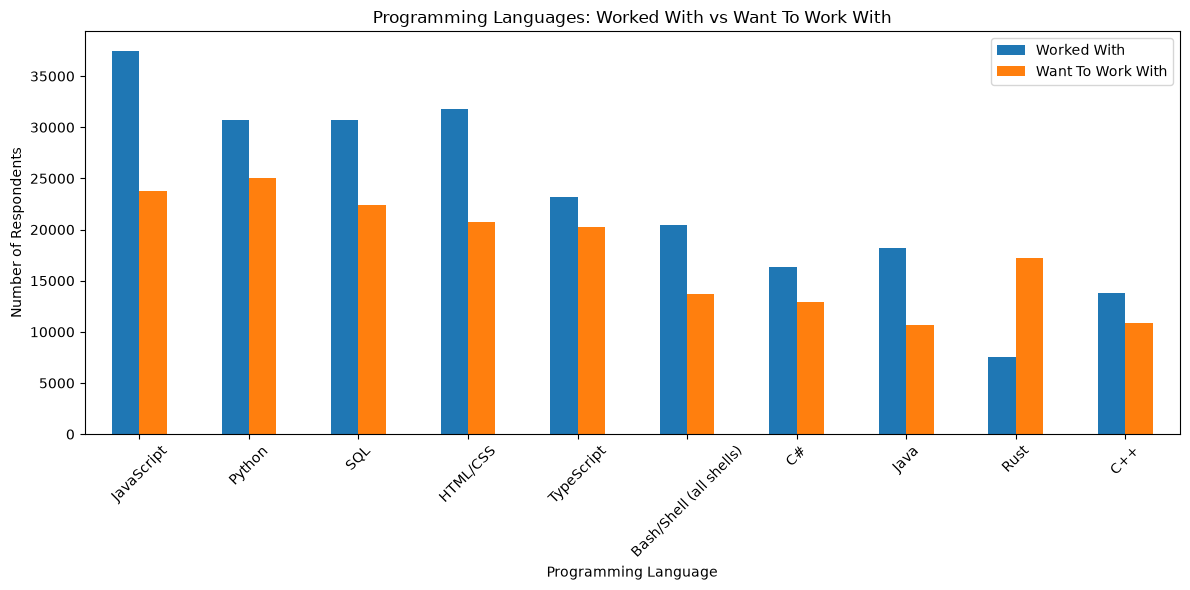

In [11]:
from collections import Counter

worked = Counter()
wanted = Counter()

for langs in df['LanguageHaveWorkedWith'].dropna():
    worked.update(lang.strip() for lang in langs.split(';'))

for langs in df['LanguageWantToWorkWith'].dropna():
    wanted.update(lang.strip() for lang in langs.split(';'))

language_counts = pd.DataFrame({'Worked With' : pd.Series(worked), 'Want To Work With' : pd.Series(wanted)}).fillna(0)

top_languages = language_counts.sum(axis = 1).sort_values(ascending = False).head(10).index

language_counts.loc[top_languages].plot(kind = 'bar', figsize = (12, 6))

plt.title('Programming Languages: Worked With vs Want To Work With')
plt.xlabel('Programming Language')
plt.ylabel('Number of Respondents')
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

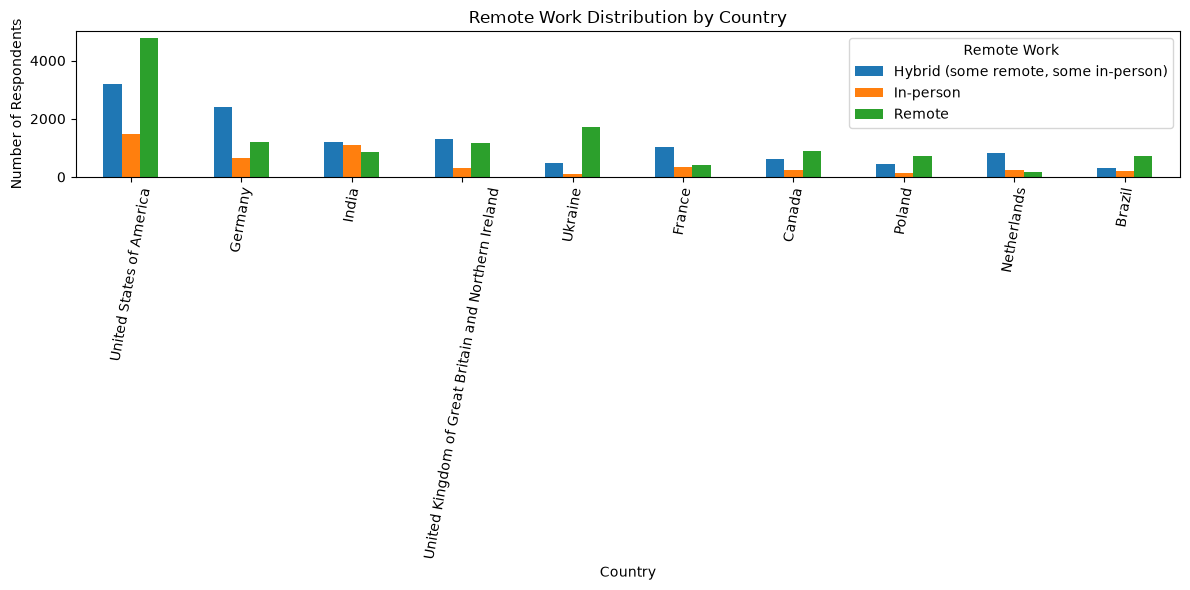

In [15]:
remote_region = pd.crosstab(df['Country'], df['RemoteWork'])
top_countries = df['Country'].value_counts().head(10).index

remote_region.loc[top_countries].plot(kind = 'bar', figsize = (12, 6))

plt.title('Remote Work Distribution by Country')
plt.xlabel('Country')
plt.ylabel('Number of Respondents')
plt.legend(title = 'Remote Work')
plt.xticks(rotation = 80)
plt.tight_layout()
plt.show()

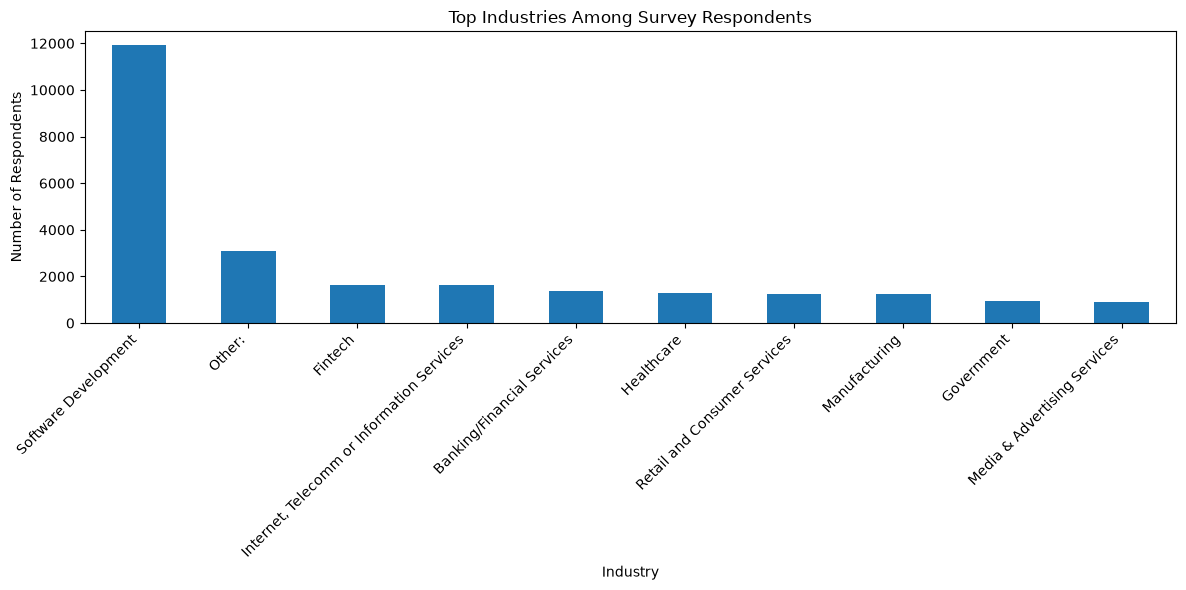

In [16]:
industry_counts = df['Industry'].value_counts()

top_industries = industry_counts.head(10)

plt.figure(figsize=(12,6))
top_industries.plot(kind='bar')

plt.title('Top Industries Among Survey Respondents')
plt.xlabel('Industry')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [17]:
comp_stats = df['ConvertedCompYearly'].describe()

threshold = comp_stats['mean'] + (3 * comp_stats['std'])

high_comp = df[df['ConvertedCompYearly'] > threshold]
print('Number of extreme compensation values:', len(high_comp))

Number of extreme compensation values: 89


Number of outliers: 979


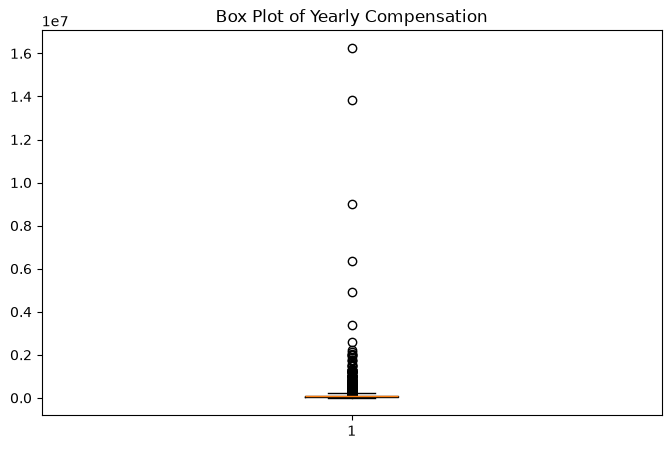

In [18]:
IQR = comp_stats['75%'] - comp_stats['25%']
lower_bound = comp_stats['25%'] - (1.5 * IQR)
upper_bound = comp_stats['75%'] + (1.5 * IQR)

outliers = df[(df['ConvertedCompYearly'] < lower_bound) | (df['ConvertedCompYearly'] > upper_bound)]

print('Number of outliers:', len(outliers))

plt.figure(figsize = (8, 5))

plt.boxplot(df['ConvertedCompYearly'].dropna())
plt.title('Box Plot of Yearly Compensation')

plt.show()

In [19]:
df_clean = df[
    (df['ConvertedCompYearly'] >= lower_bound) &
    (df['ConvertedCompYearly'] <= upper_bound)
]
print("Original dataset size:", df.shape)
print("Cleaned dataset size:", df_clean.shape)

Original dataset size: (65457, 115)
Cleaned dataset size: (22458, 115)


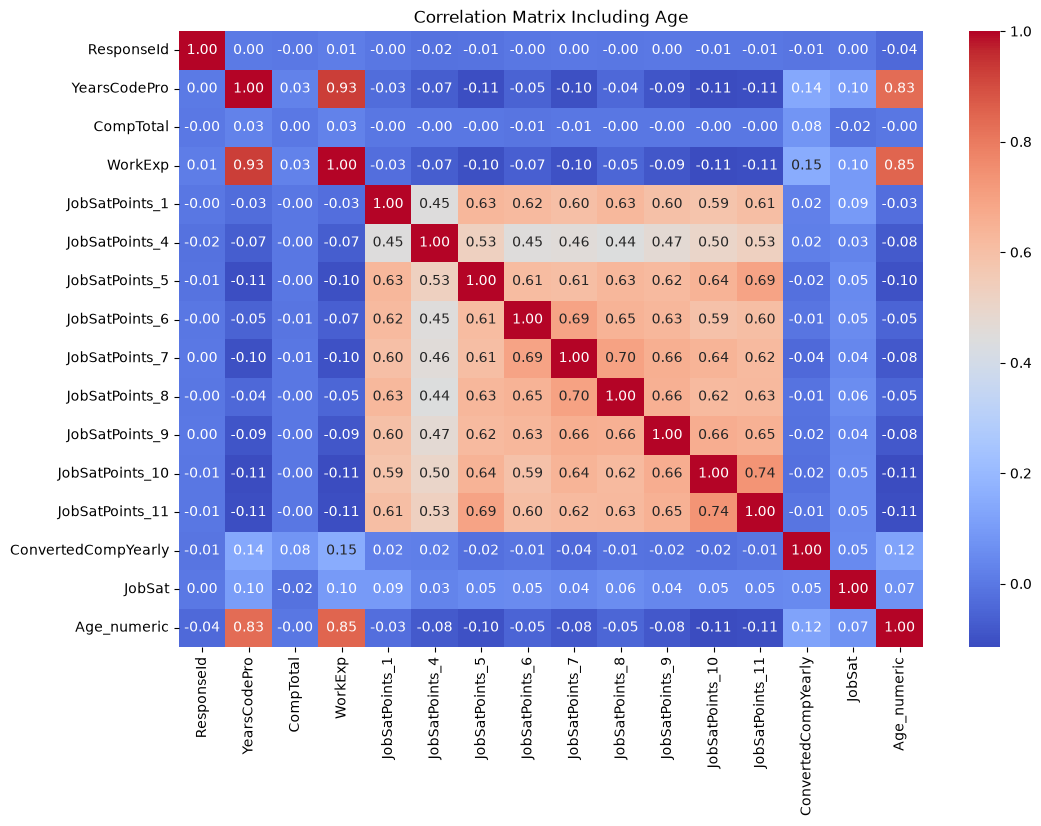

In [20]:
age_mapping = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 30,
    '35-44 years old': 40,
    '45-54 years old': 50,
    '55-64 years old': 60,
    '65 years or older': 65,
    'Prefer not to say': np.nan
}

df['Age_numeric'] = df['Age'].map(age_mapping)

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

age_corr = df[numeric_cols].corr()['Age_numeric'].sort_values(ascending=False)

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix Including Age')
plt.show()

# Key Findings

# Conclusion